In [12]:
import os
import numpy as np
import pandas as pd

# Kaggle input dosyalarını listele
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))


# YOLO / Ultralytics
!pip install -q ultralytics iterative-stratification

import ultralytics

ultralytics.checks()

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7037.7/8156.9 GB disk)


In [13]:
INPUT_DIR = "/kaggle/input"

for root, dirs, files in os.walk(INPUT_DIR):
    print(root)
    for file in files[:5]:
        print("   ", file)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/elifezgiyldz
/kaggle/input/datasets/elifezgiyldz/vehicles
/kaggle/input/datasets/elifezgiyldz/vehicles/vehicle_dataset
/kaggle/input/datasets/elifezgiyldz/vehicles/vehicle_dataset/labels
    img_005445.txt
    img_007650.txt
    img_004156.txt
    img_003972.txt
    img_002521.txt
/kaggle/input/datasets/elifezgiyldz/vehicles/vehicle_dataset/images
    img_001954.jpg
    img_003179.jpg
    img_000202.jpg
    img_007409.jpg
    img_008539.jpg
/kaggle/input/models
/kaggle/input/models/elifezgiyldz
/kaggle/input/models/elifezgiyldz/best-3
/kaggle/input/models/elifezgiyldz/best-3/pytorch
/kaggle/input/models/elifezgiyldz/best-3/pytorch/default
/kaggle/input/models/elifezgiyldz/best-3/pytorch/default/1
    best-3.pt


In [15]:
# ============================================
# 3. DATASET PATHS
# ============================================

SOURCE_DIR = "/kaggle/input/datasets/elifezgiyldz/vehicles/vehicle_dataset"

IMAGE_DIR = os.path.join(SOURCE_DIR, "images")
LABEL_DIR = os.path.join(SOURCE_DIR, "labels")

print("IMAGE_DIR:", IMAGE_DIR)
print("LABEL_DIR:", LABEL_DIR)

print("\nImages directory exists:",
      os.path.exists(IMAGE_DIR))

print("Labels directory exists:",
      os.path.exists(LABEL_DIR))

IMAGE_DIR: /kaggle/input/datasets/elifezgiyldz/vehicles/vehicle_dataset/images
LABEL_DIR: /kaggle/input/datasets/elifezgiyldz/vehicles/vehicle_dataset/labels

Images directory exists: True
Labels directory exists: True


In [16]:
# ============================================
# 4. CHECK IMAGES / LABELS
# ============================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}

images = [
    f
    for f in os.listdir(IMAGE_DIR)
    if os.path.splitext(f)[1].lower()
    in IMAGE_EXTENSIONS
]

labels = [
    f
    for f in os.listdir(LABEL_DIR)
    if f.endswith(".txt")
]

print("Total images:", len(images))
print("Total labels:", len(labels))

Total images: 6471
Total labels: 6471


In [17]:
# ============================================
# 5. CHECK IMAGE-LABEL MATCHING
# ============================================

image_bases = {
    os.path.splitext(f)[0]
    for f in images
}

label_bases = {
    os.path.splitext(f)[0]
    for f in labels
}

images_without_labels = sorted(
    image_bases - label_bases
)

labels_without_images = sorted(
    label_bases - image_bases
)

print("Images without labels:", len(images_without_labels))
print("Labels without images:", len(labels_without_images))

if images_without_labels:
    print("\nImages without labels:")
    print(images_without_labels[:20])

if labels_without_images:
    print("\nLabels without images:")
    print(labels_without_images[:20])

Images without labels: 0
Labels without images: 0


In [18]:
# ============================================
# 6. CHECK EMPTY LABEL FILES
# ============================================

empty_labels = []

for label_file in labels:

    label_path = os.path.join(
        LABEL_DIR,
        label_file
    )

    if os.path.getsize(label_path) == 0:
        empty_labels.append(label_file)

print("Total empty label files:", len(empty_labels))

if empty_labels:
    print("\nFirst 20 empty labels:")
    print(empty_labels[:20])

Total empty label files: 290

First 20 empty labels:
['img_006800.txt', 'img_002002.txt', 'img_000113.txt', 'img_005698.txt', 'img_000915.txt', 'img_005512.txt', 'img_003444.txt', 'img_000105.txt', 'img_008157.txt', 'img_000550.txt', 'img_003850.txt', 'img_007582.txt', 'img_008311.txt', 'img_000187.txt', 'img_008308.txt', 'img_001197.txt', 'img_000243.txt', 'img_004514.txt', 'img_001648.txt', 'img_003312.txt']


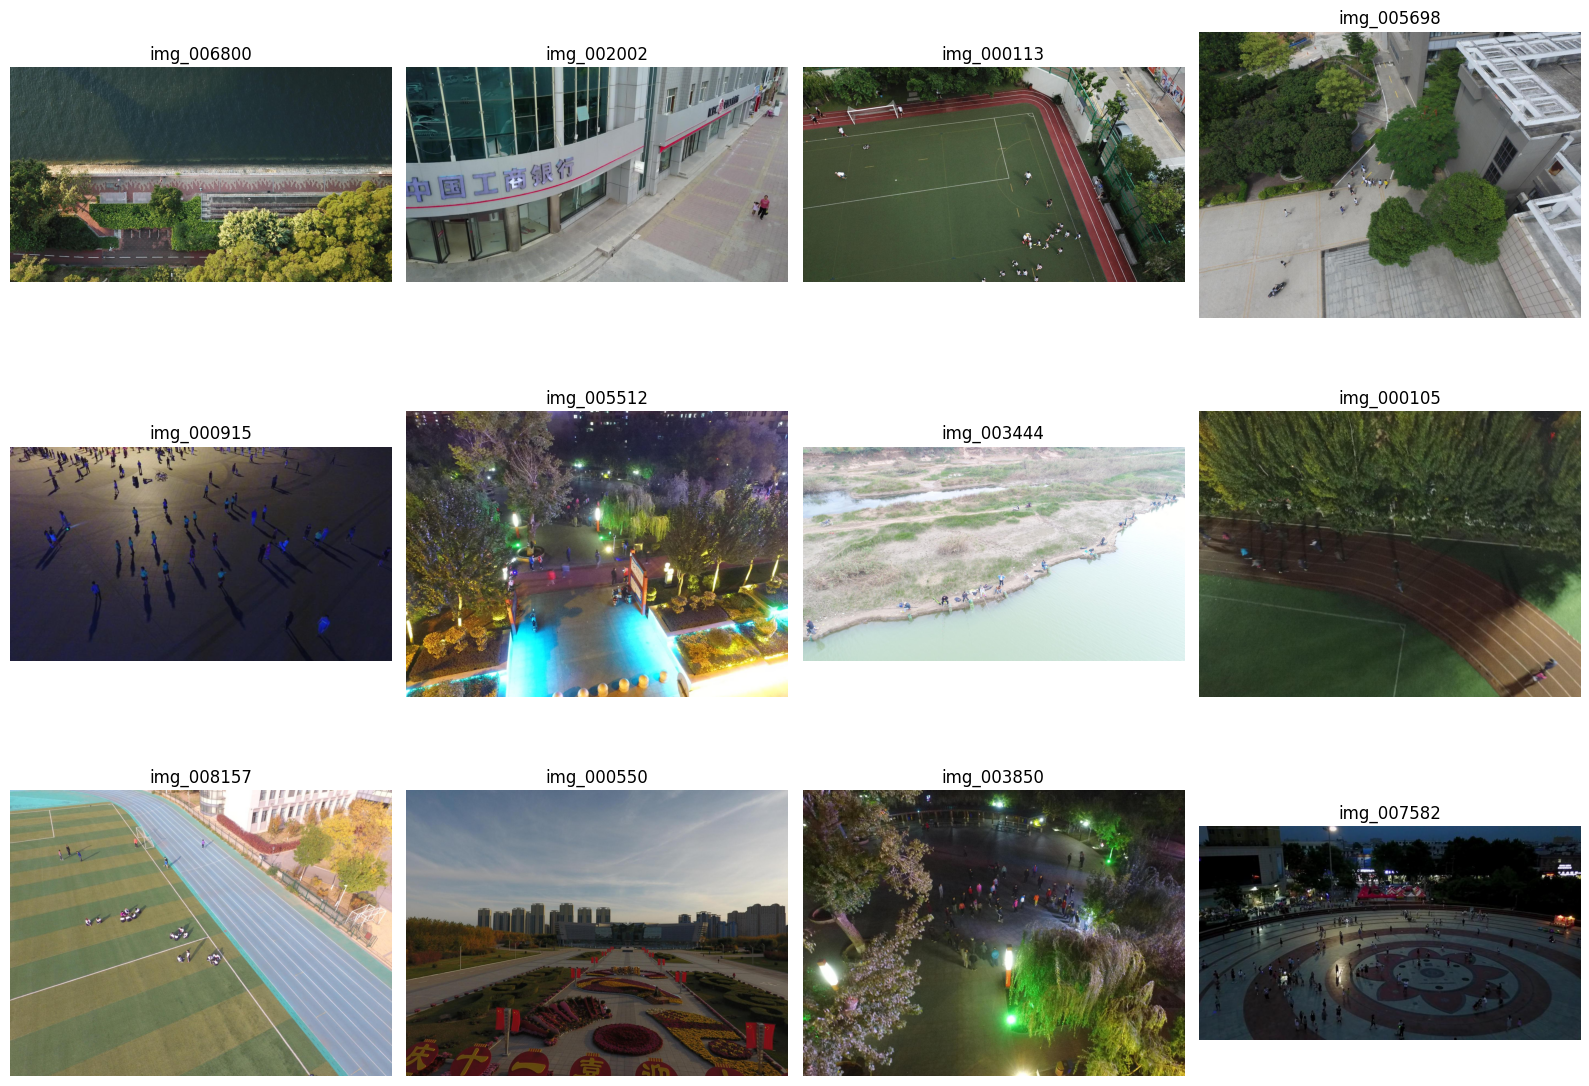

In [19]:
# ============================================
# 7. VISUAL CHECK OF EMPTY LABEL IMAGES
# ============================================

import matplotlib.pyplot as plt
from PIL import Image

# İlk 12 boş label
sample_empty = empty_labels[:12]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, label_file in zip(axes, sample_empty):

    image_file = os.path.splitext(label_file)[0]

    # Uzantıyı bul
    possible_extensions = [".jpg", ".jpeg", ".png", ".bmp"]

    image_path = None

    for ext in possible_extensions:
        candidate = os.path.join(IMAGE_DIR, image_file + ext)

        if os.path.exists(candidate):
            image_path = candidate
            break

    if image_path:
        img = Image.open(image_path)

        ax.imshow(img)
        ax.set_title(image_file)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
total_images = len(images)
empty_count = len(empty_labels)
non_empty_count = total_images - empty_count

print(f"Total images: {total_images}")
print(f"Empty labels: {empty_count}")
print(f"Non-empty labels: {non_empty_count}")

print(f"\nEmpty ratio: {empty_count / total_images * 100:.2f}%")
print(f"Non-empty ratio: {non_empty_count / total_images * 100:.2f}%")

Total images: 6471
Empty labels: 290
Non-empty labels: 6181

Empty ratio: 4.48%
Non-empty ratio: 95.52%


In [21]:
# ============================================
# 7. CLASS DISTRIBUTION
# ============================================

from collections import Counter

CLASS_NAMES = ["car", "van", "truck", "bus"]

class_counts = Counter()

for label_file in labels:

    label_path = os.path.join(LABEL_DIR, label_file)

    with open(label_path, "r") as f:
        for line in f:

            parts = line.strip().split()

            # Boş label dosyalarını atla
            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            class_counts[class_id] += 1


total_annotations = sum(class_counts.values())

print("Total annotations:", total_annotations)
print()

for class_id, class_name in enumerate(CLASS_NAMES):

    count = class_counts[class_id]
    percentage = count / total_annotations * 100

    print(
        f"{class_id}: {class_name:8s} "
        f"{count:7d} "
        f"({percentage:6.2f}%)"
    )

Total annotations: 165349

0: car       124843 ( 75.50%)
1: van        22787 ( 13.78%)
2: truck      12109 (  7.32%)
3: bus         5610 (  3.39%)


In [23]:
!pip install -q iterative-stratification

In [24]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
import numpy as np
import os

In [25]:
# ============================================
# 9. CREATE IMAGE-LEVEL CLASS MATRIX
# ============================================

CLASS_NAMES = ["car", "van", "truck", "bus"]
NUM_CLASSES = len(CLASS_NAMES)

RANDOM_STATE = 42

images = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if os.path.splitext(f)[1].lower()
    in {".jpg", ".jpeg", ".png", ".bmp"}
])

# Her görüntü için:
# [car, van, truck, bus]
#
# Örnek:
# [1, 0, 1, 0] -> car + truck var
# [1, 0, 0, 0] -> sadece car var
# [0, 0, 0, 0] -> araç yok

Y = np.zeros(
    (len(images), NUM_CLASSES),
    dtype=int
)

for i, image_name in enumerate(images):

    base_name = os.path.splitext(image_name)[0]

    label_path = os.path.join(
        LABEL_DIR,
        base_name + ".txt"
    )

    if not os.path.exists(label_path):
        continue

    with open(label_path, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            if 0 <= class_id < NUM_CLASSES:
                Y[i, class_id] = 1


print("Images:", len(images))
print("Y shape:", Y.shape)

Images: 6471
Y shape: (6471, 4)


In [27]:
# ============================================
# 10. IMAGE-LEVEL CLASS DISTRIBUTION
# ============================================

for class_id, class_name in enumerate(CLASS_NAMES):

    count = Y[:, class_id].sum()

    print(
        f"{class_name:8s}: "
        f"{count:5d} images "
        f"({count / len(images) * 100:6.2f}%)"
    )

negative_images = np.sum(Y.sum(axis=1) == 0)

print(
    f"\nNo-vehicle images: "
    f"{negative_images} "
    f"({negative_images / len(images) * 100:.2f}%)"
)

car     :  6103 images ( 94.31%)
van     :  4850 images ( 74.95%)
truck   :  3494 images ( 53.99%)
bus     :  1954 images ( 30.20%)

No-vehicle images: 290 (4.48%)


In [28]:
# ============================================
# 11. TRAIN / VALIDATION / TEST SPLIT
# ============================================

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

TRAIN_RATIO = 0.70
VAL_RATIO = 0.20
TEST_RATIO = 0.10

RANDOM_STATE = 42

# --------------------------------------------
# STEP 1
# Train = 70%
# Temporary = 30%
# --------------------------------------------

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=VAL_RATIO + TEST_RATIO,
    random_state=RANDOM_STATE
)

train_idx, temp_idx = next(
    splitter.split(images, Y)
)

# --------------------------------------------
# STEP 2
# Temporary set:
# Validation = 20 / 30 = 66.67%
# Test       = 10 / 30 = 33.33%
# --------------------------------------------

temp_images = [images[i] for i in temp_idx]
temp_Y = Y[temp_idx]

test_ratio_inside_temp = TEST_RATIO / (
    VAL_RATIO + TEST_RATIO
)

splitter_temp = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=test_ratio_inside_temp,
    random_state=RANDOM_STATE
)

val_relative_idx, test_relative_idx = next(
    splitter_temp.split(temp_images, temp_Y)
)

val_idx = [temp_idx[i] for i in val_relative_idx]
test_idx = [temp_idx[i] for i in test_relative_idx]

# --------------------------------------------
# Final image lists
# --------------------------------------------

train_images = [images[i] for i in train_idx]
val_images = [images[i] for i in val_idx]
test_images = [images[i] for i in test_idx]

print("Train      :", len(train_images))
print("Validation :", len(val_images))
print("Test       :", len(test_images))
print("Total      :", len(train_images) + len(val_images) + len(test_images))

Train      : 4529
Validation : 1294
Test       : 648
Total      : 6471


In [29]:
# ============================================
# 12. CHECK SPLIT DISTRIBUTION
# ============================================

def print_split_distribution(split_name, indices):

    split_Y = Y[indices]

    print(f"\n{'=' * 45}")
    print(f"{split_name.upper()}")
    print(f"{'=' * 45}")

    print(f"Images: {len(indices)}\n")

    for class_id, class_name in enumerate(CLASS_NAMES):

        count = split_Y[:, class_id].sum()
        percentage = count / len(indices) * 100

        print(
            f"{class_name:8s}: "
            f"{count:5d} images "
            f"({percentage:6.2f}%)"
        )

    negative = np.sum(split_Y.sum(axis=1) == 0)

    print(
        f"\nNo-vehicle: "
        f"{negative:5d} images "
        f"({negative / len(indices) * 100:6.2f}%)"
    )


print_split_distribution("Train", train_idx)
print_split_distribution("Validation", val_idx)
print_split_distribution("Test", test_idx)


TRAIN
Images: 4529

car     :  4271 images ( 94.30%)
van     :  3394 images ( 74.94%)
truck   :  2445 images ( 53.99%)
bus     :  1368 images ( 30.21%)

No-vehicle:   200 images (  4.42%)

VALIDATION
Images: 1294

car     :  1221 images ( 94.36%)
van     :   970 images ( 74.96%)
truck   :   699 images ( 54.02%)
bus     :   390 images ( 30.14%)

No-vehicle:    59 images (  4.56%)

TEST
Images: 648

car     :   611 images ( 94.29%)
van     :   486 images ( 75.00%)
truck   :   350 images ( 54.01%)
bus     :   196 images ( 30.25%)

No-vehicle:    31 images (  4.78%)


In [30]:
# ============================================
# 13. CREATE TRAIN / VAL / TEST DIRECTORIES
# ============================================

import shutil
import os

OUTPUT_DIR = "/kaggle/working/dataset_split"

for split in ["train", "val", "test"]:

    os.makedirs(
        os.path.join(OUTPUT_DIR, "images", split),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(OUTPUT_DIR, "labels", split),
        exist_ok=True
    )

print("Directories created:")
print(OUTPUT_DIR)

Directories created:
/kaggle/working/dataset_split


In [31]:
# ============================================
# 14. COPY IMAGES AND LABELS
# ============================================

def copy_split(image_list, split):

    for image_name in image_list:

        base_name = os.path.splitext(image_name)[0]

        # Source
        image_src = os.path.join(
            IMAGE_DIR,
            image_name
        )

        label_src = os.path.join(
            LABEL_DIR,
            base_name + ".txt"
        )

        # Destination
        image_dst = os.path.join(
            OUTPUT_DIR,
            "images",
            split,
            image_name
        )

        label_dst = os.path.join(
            OUTPUT_DIR,
            "labels",
            split,
            base_name + ".txt"
        )

        shutil.copy2(image_src, image_dst)
        shutil.copy2(label_src, label_dst)


copy_split(train_images, "train")
copy_split(val_images, "val")
copy_split(test_images, "test")

print("Dataset split copied successfully.")

Dataset split copied successfully.


In [32]:
# ============================================
# 15. VERIFY SPLIT FILE COUNTS
# ============================================

for split in ["train", "val", "test"]:

    image_dir = os.path.join(
        OUTPUT_DIR,
        "images",
        split
    )

    label_dir = os.path.join(
        OUTPUT_DIR,
        "labels",
        split
    )

    image_count = len(os.listdir(image_dir))
    label_count = len(os.listdir(label_dir))

    print(
        f"{split:5s} -> "
        f"images: {image_count:4d}, "
        f"labels: {label_count:4d}"
    )

train -> images: 4529, labels: 4529
val   -> images: 1294, labels: 1294
test  -> images:  648, labels:  648


In [34]:
# ============================================
# 16. CREATE YOLO data.yaml
# ============================================

CLASS_NAMES = ["car", "van", "truck", "bus"]

yaml_content = f"""
path: {OUTPUT_DIR}

train: images/train
val: images/val
test: images/test

names:
"""

for i, name in enumerate(CLASS_NAMES):
    yaml_content += f"  {i}: {name}\n"

YAML_PATH = "/kaggle/working/data.yaml"

with open(YAML_PATH, "w") as f:
    f.write(yaml_content)

print(yaml_content)


path: /kaggle/working/dataset_split

train: images/train
val: images/val
test: images/test

names:
  0: car
  1: van
  2: truck
  3: bus



In [35]:
# ============================================
# 17. VERIFY data.yaml
# ============================================

with open(YAML_PATH, "r") as f:
    print(f.read())


path: /kaggle/working/dataset_split

train: images/train
val: images/val
test: images/test

names:
  0: car
  1: van
  2: truck
  3: bus



In [21]:
# ============================================
# 18. CHECK GPU + ULTRALYTICS
# ============================================

import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU bulunamadı!")

Ultralytics version: 8.4.163
CUDA available: True
GPU: Tesla T4


In [25]:
# ============================================
# 19. YOLO11s BASELINE TRAINING
# ============================================

from ultralytics import YOLO

MODEL_NAME = "yolo11m.pt"
EXPERIMENT_NAME = "E1_yolo11m_960"
YAML_PATH = "data.yaml"

model = YOLO(MODEL_NAME)

results = model.train(
    data=YAML_PATH,

    epochs=30,
    imgsz=960,

    # 2 GPU
    device=[0, 1],
    batch=16,  # toplam batch; OOM durumuna göre düşürürüz

    # Optimizer
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,
    cos_lr=True,

    # Augmentation
    mosaic=1.0,
    close_mosaic=15,
    mixup=0.05,

    degrees=5.0,
    translate=0.1,
    scale=0.4,
    fliplr=0.5,

    # Training
    patience=30,
    seed=42,

    project="/kaggle/working/runs",
    name=EXPERIMENT_NAME,

    plots=True
)



Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data.yaml, degrees=5.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, m

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/30       9.4G      1.241      1.085     0.9991         10        960: 100% ━━━━━━━━━━━━ 284/284 1.9it/s 2:330.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 2.9it/s 14.0s0.4s
                   all       1294      31982      0.567      0.497      0.505       0.33

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      9.51G      1.221      1.035     0.9963         16        960: 100% ━━━━━━━━━━━━ 284/284 1.9it/s 2:320.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 3.3it/s 12.3s0.3s
                   all       1294      31982      0.642      0.475      0.519      0.345

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30       9.6G      1.214      1.005      0.989         87        9

In [26]:
# ============================================
# 20. FINAL TEST EVALUATION
# ============================================

test_metrics = model.val(
    data=YAML_PATH,
    split="test"
)

print("\n===== TEST RESULTS =====")

print(f"mAP50:     {test_metrics.box.map50:.4f}")
print(f"mAP50-95:  {test_metrics.box.map:.4f}")
print(f"Precision: {test_metrics.box.mp:.4f}")
print(f"Recall:    {test_metrics.box.mr:.4f}")

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1787.1±434.9 MB/s, size: 259.5 KB)
val: Scanning /kaggle/working/dataset_split/labels/test.cache... 648 images, 31 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 648/648 97.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 1.2it/s 34.3s0.9ss
                   all        648      17107      0.783      0.691      0.751      0.541
                   car        611      13146      0.855      0.839      0.891      0.633
                   van        486       2250      0.693      0.587      0.646      0.476
                 truck        350       1177      0.777      0.575      0.674      0.471
                   bus        196        534      0.808      0.762      0.794      0.583
Speed: 1.9ms preprocess

In [27]:
# ============================================
# 21. PER-CLASS TEST RESULTS
# ============================================

print("\n===== PER-CLASS RESULTS =====")

for class_id, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:8s} | "
        f"mAP50-95: {test_metrics.box.maps[class_id]:.4f}"
    )


===== PER-CLASS RESULTS =====
car      | mAP50-95: 0.6330
van      | mAP50-95: 0.4763
truck    | mAP50-95: 0.4714
bus      | mAP50-95: 0.5831


In [28]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/runs/E1_yolo11m_960-2/weights/best.pt")

metrics = model.val(
    data="data.yaml",
    split="val",
    imgsz=960,
    plots=True
)

print(metrics.confusion_matrix.matrix)

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2351.8±437.0 MB/s, size: 209.9 KB)
val: Scanning /kaggle/working/dataset_split/labels/val.cache... 1294 images, 59 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1294/1294 169.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 81/81 1.2it/s 1:060.9sss
                   all       1294      31982      0.791      0.706      0.773      0.568
                   car       1221      23872      0.853      0.849      0.896      0.641
                   van        970       4437      0.699      0.612      0.675      0.502
                 truck        699       2475      0.786       0.64      0.722      0.515
                   bus        390       1198      0.825      0.725      0.798      0.614
Speed: 1.6ms preproc

In [3]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 4.5 MB/s eta 0:00:00


In [6]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("best-3.pt"):
    print(p)

/kaggle/input/models/elifezgiyldz/best-3/pytorch/default/1/best-3.pt


In [36]:
from pathlib import Path

yamls = list(Path("/kaggle").rglob("data.yaml"))

for y in yamls:
    print(y)

/kaggle/working/data.yaml


In [37]:
from ultralytics import YOLO

# 30 epoch eğittiğin modelin BEST checkpoint'i
model = YOLO(
    "/kaggle/input/models/elifezgiyldz/best-3/pytorch/default/1/best-3.pt"
)

DATA_YAML = "/kaggle/working/data.yaml"

results = model.train(
    
    data=DATA_YAML,

    # Fine-tuning
    epochs=15,
    imgsz=1280,
    batch=8,              # OOM olursa 4'e düşür
    device=[0, 1],

    # Daha düşük learning rate
    optimizer="AdamW",
    lr0=0.0002,
    weight_decay=0.0005,
    cos_lr=True,

    # Hafif augmentation
    mosaic=0.3,
    close_mosaic=5,
    mixup=0.0,
    degrees=2.0,
    translate=0.05,
    scale=0.2,
    fliplr=0.5,

    # 15 epoch zaten kısa, early stopping'e pek ihtiyaç yok
    patience=15,

    seed=42,

    project="/kaggle/working/runs",
    name="FT_yolo11m_1280_15ep",

    plots=True
)

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=2.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/input/models/elife

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/15      8.29G     0.9377     0.6444      0.946         34       1280: 100% ━━━━━━━━━━━━ 567/567 2.2it/s 4:130.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 81/81 4.6it/s 17.7s0.2s
                   all       1294      31982      0.794      0.725      0.787      0.579

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/15      8.29G     0.9243     0.6308     0.9433         14       1280: 100% ━━━━━━━━━━━━ 567/567 2.2it/s 4:130.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 81/81 4.6it/s 17.7s0.2s
                   all       1294      31982        0.8      0.717      0.788       0.58

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/15      8.34G     0.9205     0.6333     0.9366         11       12

In [38]:
from ultralytics import YOLO

model = YOLO(
    "/kaggle/working/runs/FT_yolo11m_1280_15ep-3/weights/best.pt"
)

metrics = model.val(
    data="/kaggle/working/data.yaml",
    split="test",
    imgsz=1280,
    batch=8,
    device=0,
    plots=True
)

print("\n===== TEST RESULTS =====")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")

print("\n===== PER-CLASS RESULTS =====")
for i, name in model.names.items():
    print(f"{name:8s} | mAP50-95: {metrics.box.maps[i]:.4f}")

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3240.1±615.7 MB/s, size: 257.9 KB)
val: Scanning /kaggle/working/dataset_split/labels/test... 648 images, 31 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 648/648 1.2Kit/s 0.5s0.0ss
val: New cache created: /kaggle/working/dataset_split/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 81/81 1.7it/s 47.4s0.7ss
                   all        648      17107      0.792      0.731      0.785      0.574
                   car        611      13146      0.868      0.866      0.911      0.665
                   van        486       2250      0.728      0.633      0.691      0.514
                 truck        350       1177      0.763      0.653       0.71      0.503
                   bus        196        5

In [39]:
!pip install -q ImageHash

In [41]:
import shutil
import os

SOURCE = "/kaggle/working/dataset_split"
OUTPUT = "/kaggle/working/split_dataset"

shutil.make_archive(
    OUTPUT,
    "zip",
    SOURCE
)

print("Oluşturuldu:")
print(OUTPUT + ".zip")
print("Boyut:", os.path.getsize(OUTPUT + ".zip") / (1024**3), "GB")

Oluşturuldu:
/kaggle/working/split_dataset.zip
Boyut: 1.4433360053226352 GB


In [44]:
from pathlib import Path
from PIL import Image
import imagehash

DATASET_ROOT = "/kaggle/working/dataset_split"

folders = {
    "train": Path(DATASET_ROOT) / "images/train",
    "val":   Path(DATASET_ROOT) / "images/val",
    "test":  Path(DATASET_ROOT) / "images/test",
}

def calculate_hashes(folder):
    hashes = {}

    for path in folder.iterdir():
        if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            try:
                with Image.open(path) as img:
                    hashes[path.name] = imagehash.phash(img)
            except Exception as e:
                print("Hata:", path, e)

    return hashes


print("Hash'ler hesaplanıyor...")

train_hashes = calculate_hashes(folders["train"])
val_hashes   = calculate_hashes(folders["val"])
test_hashes  = calculate_hashes(folders["test"])

print("Train:", len(train_hashes))
print("Val:", len(val_hashes))
print("Test:", len(test_hashes))

Hash'ler hesaplanıyor...
Train: 4529
Val: 1294
Test: 648
